In [1]:
# Day 21 - Project Overview

project_overview = """
Project Title: EconoCausal - Dynamic Pricing via Double Machine Learning

Objective:
To explore the relationship between product price and quantity
using Double Machine Learning (DML) on the UCI Online Retail dataset.

Dataset:
UCI Online Retail dataset containing historical retail transactions.

Treatment:
UnitPrice

Outcome:
Quantity

Preferred Model:
Product and time controls

Controls:
StockCode, Month, Hour, DayOfWeek

Preliminary Coefficient:
-0.002905

Note:
The dataset is observational. The preliminary coefficient should
not be interpreted as a confirmed causal effect.
"""

print(project_overview)


Project Title: EconoCausal - Dynamic Pricing via Double Machine Learning

Objective:
To explore the relationship between product price and quantity
using Double Machine Learning (DML) on the UCI Online Retail dataset.

Dataset:
UCI Online Retail dataset containing historical retail transactions.

Treatment:
UnitPrice

Outcome:
Quantity

Preferred Model:
Product and time controls

Controls:
StockCode, Month, Hour, DayOfWeek

Preliminary Coefficient:
-0.002905

Note:
The dataset is observational. The preliminary coefficient should
not be interpreted as a confirmed causal effect.



In [2]:
# Dataset and Methodology

methodology = """
Dataset:
UCI Online Retail dataset.

Data Preparation:
- Removed duplicate records.
- Converted InvoiceDate to datetime format.
- Filtered non-positive UnitPrice and Quantity records.
- Created Month, Hour and DayOfWeek features.

Method:
Double Machine Learning (DML).

Treatment:
UnitPrice

Outcome:
Quantity

Controls:
StockCode, Month, Hour and DayOfWeek.

Model Comparison:
Compared preliminary estimates from time-only controls
and product plus time controls.
"""

print(methodology)


Dataset:
UCI Online Retail dataset.

Data Preparation:
- Removed duplicate records.
- Converted InvoiceDate to datetime format.
- Filtered non-positive UnitPrice and Quantity records.
- Created Month, Hour and DayOfWeek features.

Method:
Double Machine Learning (DML).

Treatment:
UnitPrice

Outcome:
Quantity

Controls:
StockCode, Month, Hour and DayOfWeek.

Model Comparison:
Compared preliminary estimates from time-only controls
and product plus time controls.



In [3]:
# Results and Discussion

results_discussion = """
Results:
- Time controls only: -0.005836
- Product and time controls: -0.002905

Discussion:
The preliminary coefficient changes after adding product controls.
This suggests that product identity may be important when
examining the price-quantity relationship.

The product and time controls specification is selected as
the preferred model for further validation.

These preliminary estimates do not establish causality.
"""

print(results_discussion)


Results:
- Time controls only: -0.005836
- Product and time controls: -0.002905

Discussion:
The preliminary coefficient changes after adding product controls.
This suggests that product identity may be important when
examining the price-quantity relationship.

The product and time controls specification is selected as
the preferred model for further validation.

These preliminary estimates do not establish causality.



In [4]:
# Limitations and Conclusion

limitations_conclusion = """
Limitations:
- The dataset is observational.
- Unobserved confounding may affect the estimates.
- Preliminary estimates vary across model specifications.
- Non-positive prices and quantities were excluded.
- The results should not be treated as confirmed causal effects.

Conclusion:
This project explored the price-quantity relationship using
Double Machine Learning on the UCI Online Retail dataset.

Product and time controls were selected as the preferred
specification based on preliminary model comparison.

Further validation is required before using the findings
for real-world pricing decisions.
"""

print(limitations_conclusion)


Limitations:
- The dataset is observational.
- Unobserved confounding may affect the estimates.
- Preliminary estimates vary across model specifications.
- Non-positive prices and quantities were excluded.
- The results should not be treated as confirmed causal effects.

Conclusion:
This project explored the price-quantity relationship using
Double Machine Learning on the UCI Online Retail dataset.

Product and time controls were selected as the preferred
specification based on preliminary model comparison.

Further validation is required before using the findings
for real-world pricing decisions.



In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving Online Retail.xlsx to Online Retail.xlsx
Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Dataset overview

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Number of rows: 541909
Number of columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate records: 5268


In [7]:
# Remove duplicate records
df_clean = df.drop_duplicates().copy()

# Convert InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Filter valid positive price and quantity records
df_clean = df_clean[
    (df_clean["UnitPrice"] > 0) &
    (df_clean["Quantity"] > 0)
].copy()

print("Clean dataset shape:", df_clean.shape)
df_clean.head()

Clean dataset shape: (524878, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
# Calculate sales
df_clean["TotalSales"] = (
    df_clean["UnitPrice"] * df_clean["Quantity"]
)

# Display key statistics
print("Average Unit Price:", df_clean["UnitPrice"].mean())
print("Average Quantity:", df_clean["Quantity"].mean())
print("Total Sales:", df_clean["TotalSales"].sum())
print("Unique Products:", df_clean["StockCode"].nunique())
print("Unique Customers:", df_clean["CustomerID"].nunique())

Average Unit Price: 3.9225725673394587
Average Quantity: 10.616600429052085
Total Sales: 10642110.804
Unique Products: 3922
Unique Customers: 4338


In [9]:
# Previous preliminary DML results

dml_results = pd.DataFrame({
    "Model": [
        "Time controls only",
        "Product and time controls"
    ],
    "Preliminary_Coefficient": [
        -0.005836,
        -0.002905
    ]
})

dml_results

,Model,Preliminary_Coefficient
0,Time controls only,-0.005836
1,Product and time controls,-0.002905


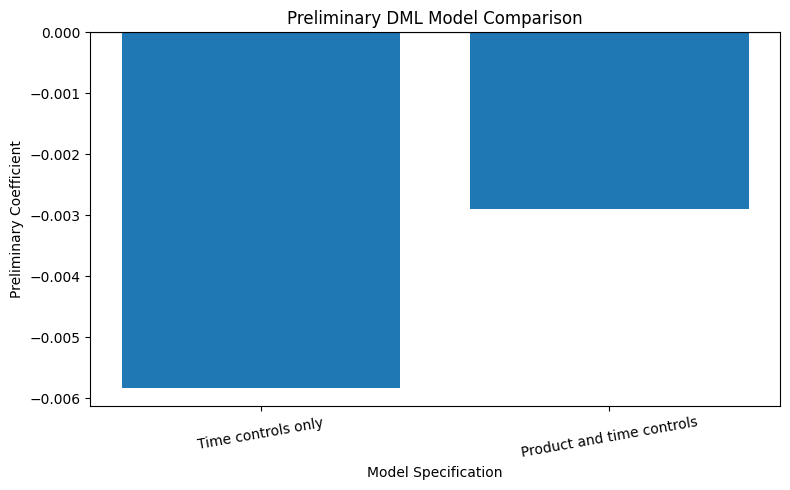

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    dml_results["Model"],
    dml_results["Preliminary_Coefficient"]
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Preliminary DML Model Comparison")
plt.xlabel("Model Specification")
plt.ylabel("Preliminary Coefficient")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [11]:
# Generate dataset summary
dataset_summary = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Original Columns",
        "Cleaned Rows",
        "Average Unit Price",
        "Average Quantity",
        "Total Sales",
        "Unique Products",
        "Unique Customers"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df_clean.shape[0],
        df_clean["UnitPrice"].mean(),
        df_clean["Quantity"].mean(),
        df_clean["TotalSales"].sum(),
        df_clean["StockCode"].nunique(),
        df_clean["CustomerID"].nunique()
    ]
})

dataset_summary

,Metric,Value
0,Original Rows,5.419090e+05
1,Original Columns,8.000000e+00
2,Cleaned Rows,5.248780e+05
3,Average Unit Price,3.922573e+00
4,Average Quantity,1.061660e+01
5,Total Sales,1.064211e+07
6,Unique Products,3.922000e+03
7,Unique Customers,4.338000e+03


In [12]:
dataset_summary.to_csv(
    "day21_dataset_summary.csv",
    index=False
)

dml_results.to_csv(
    "day21_dml_results.csv",
    index=False
)

files.download("day21_dataset_summary.csv")
files.download("day21_dml_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>